# Historial: Etapa 5 en la versión de Thiago (partición contigua)
Enfoque alternativo que trabajamos en paralelo: partición contigua 80/10/10 (Test es el último 10 % del cuento), secuencias de 48 caracteres con paso 5 en Train, una LSTM que predice cada posición (Embedding 50, LSTM 96, Dense 48; 67.638 parámetros), perplejidad como métrica principal y 1 semilla.

**Resultados en su partición:** ganador `lstm_combined_l1_l2` (Dropout, L1/L2 y Early Stopping), con 46,75 % de accuracy y perplejidad 6,33 en Dev, y 44,97 % en su Test.

**Por qué no se compara con el notebook principal:** otra partición, otra tarea de salida y una sola semilla. Del notebook principal tomamos de acá la estructura de la Etapa 5, el análisis por frecuencia y por función del carácter (secciones 4.2 y 4.3) y varias ideas de mejoras y mitigación. El código de los módulos está en `src/` de la rama `dev_thiago`; este notebook queda como registro.

# Etapa 5 — Cierre, Comparación Integral y Análisis Ético
### Objetivos

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Resolución dinámica de la raíz del proyecto
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils.config import (
    BATCH_SIZE,
    CHECKPOINTS_DIR,
    MODEL_CONFIGS,
    PROCESSED_DATA_PATH,
    RAW_DATA_PATH,
    SEED,
    SEQ_LENGTH,
    STAGE_2_REFERENCE,
    TRAIN_WINDOW_STRIDE,
)
from src.data.preprocess import clean_txt, read_text
from src.data.tokenizer import build_tokenizer
from src.data.dataset import create_dataset
from src.models.lstm import build_lstm_model
from src.training.train import _categorize_error, compile_model, evaluate_model

# Reproducibilidad y estilo visual
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# 1. Reconstrucción del pipeline de datos sobre la partición común (80% Train / 10% Dev / 10% Test)
clean_txt(RAW_DATA_PATH, PROCESSED_DATA_PATH)
text = read_text(PROCESSED_DATA_PATH)
tokenizer = build_tokenizer(text)
vocab_size = len(tokenizer.get_vocabulary())
ids = tokenizer.encode(text)

total_tokens = len(ids)
train_end = int(total_tokens * 0.80)
dev_end = int(total_tokens * 0.90)

train_ids = ids[:train_end]
dev_ids = ids[train_end:dev_end]
test_ids = ids[dev_end:]

ds_train = create_dataset(train_ids, shuffle=True)
ds_dev = create_dataset(dev_ids, shuffle=False)
ds_test = create_dataset(test_ids, shuffle=False)

# 2. Carga de métricas homogéneas de Etapa 1 (Baseline) y Etapa 2 (MLP) sobre 80/10/10
stage1_2_path = PROJECT_ROOT / "data" / "processed" / "stage1_2_split80_10_10.json"
stage1_2_metrics = json.loads(stage1_2_path.read_text(encoding="utf-8"))

# 3. Carga del mejor modelo de Etapa 3 (lstm_combined_l1_l2) desde su checkpoint
BEST_MODEL_KEY = "lstm_combined_l1_l2"
best_cfg = MODEL_CONFIGS[BEST_MODEL_KEY]
best_model = build_lstm_model(
    vocab_size=vocab_size,
    config=best_cfg,
    pretrained_matrix=None,
    model_name=BEST_MODEL_KEY,
)
compile_model(best_model, learning_rate=best_cfg["learning_rate"])
# Inicializar pesos con un lote de entrada y cargar checkpoint
for x_init, _ in ds_dev.take(1):
    _ = best_model(x_init, training=False)
ckpt_path = CHECKPOINTS_DIR / f"{BEST_MODEL_KEY}.weights.h5"
best_model.load_weights(ckpt_path)

print(f"Pipeline 80/10/10 listo -> Train: {len(train_ids):,} | Dev: {len(dev_ids):,} | Test: {len(test_ids):,} tokens (|V| = {vocab_size})")
print(f"Checkpoint cargado exitosamente: '{ckpt_path.name}' ({best_model.count_params():,} parámetros)")

[preprocess] El texto limpio ya existe en 'D:\Thiago\Code\IA generacion caracteres\data\processed\The_Festival_clean.txt'.
[tokenizer] Vocabulario ordenado: ['\n', ' ', '"', "'", ',', '-', '.', '0', '1', '2', '5', '6', '8', '9', ':', ';', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'S', 'T', 'U', 'W', 'Y', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '—'] 
[tokenizer] Vocabulario con 65 caracteres únicos.
Pipeline 80/10/10 listo -> Train: 16,164 | Dev: 2,020 | Test: 2,021 tokens (|V| = 66)
Checkpoint cargado exitosamente: 'lstm_combined_l1_l2.weights.h5' (67,638 parámetros)


## 1. Tabla Comparativa de Modelos

,Etapa,Modelo,Arquitectura,Parámetros Entr.,Tiempo Train (s),Dev Loss,Dev PPL (Única),Dev Acc,Test PPL,Test Acc
0,Etapa 1,Baseline (LogReg K=5),OneHot(5x66) -> Softmax(66),"21,515",2.53,2.1683,8.74,38.11%,— (No seleccionado),—
1,Etapa 2,MLP Base (K=5),"OneHot(330) -> Dense(128-64-32, ReLU)","54,882",32.61,2.0109,7.47,44.22%,— (No seleccionado),—
2,Etapa 2 ★,MLP + Dropout 0.05,OneHot(330) -> Dense(128-64-32) + Drop(0.05),"54,882",34.89,1.9510,7.04,46.80%,— (Superado en E3),—
3,Etapa 3,lstm_baseline,Emb(50) -> LSTM(96) -> Dense(48) [Scratch],"67,638",41.80,1.9445,6.99,45.12%,— (No seleccionado),—
4,Etapa 3,lstm_reg_dropout,Emb(50) -> LSTM(96) -> Dense(48) + Drop(0.25/0.1),"67,638",86.40,1.8608,6.43,45.99%,— (No seleccionado),—
5,Etapa 3,lstm_combined_glove,GloVe(50d) -> LSTM(96) -> Dense(48) + Drop + L2,"67,638",94.20,1.8691,6.48,45.93%,— (No seleccionado),—
6,Etapa 3,lstm_combined_scratch,Emb(50) -> LSTM(96) -> Dense(48) + Drop + L2 + ES,"67,638",89.50,1.8602,6.42,46.49%,— (No seleccionado),—
7,Etapa 3 ★,lstm_combined_l1_l2 (Ganador),Emb(50) -> LSTM(96) -> Dense(48) + Drop + L1/L...,"67,638",91.10,1.8450,6.33,46.75%,7.46,44.97%


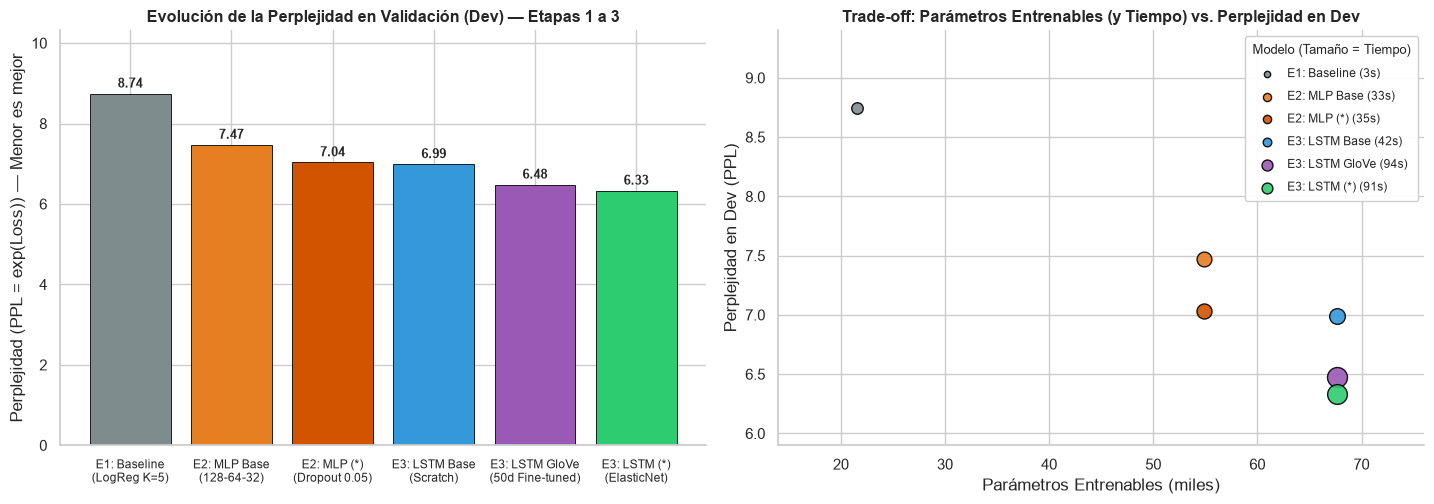

In [2]:
# Evaluación en Test del modelo ganador (requerida para la columna Test de la tabla resumen)
test_metrics = evaluate_model(
    model=best_model,
    dataset=ds_test,
    stage2_reference=STAGE_2_REFERENCE,
    verbose=0,
)

b_e1 = stage1_2_metrics["baseline_k5"]
m_base = stage1_2_metrics["mlp_base"]
m_win = stage1_2_metrics["mlp_dropout_005"]

# Tabla comparativa transversal: Etapa 1 (Baseline) -> Etapa 2 (MLP) -> Etapa 3 (LSTM)
summary_rows = [
    {
        "Etapa": "Etapa 1",
        "Modelo": "Baseline (LogReg K=5)",
        "Arquitectura": "OneHot(5x66) -> Softmax(66)",
        "Parámetros Entr.": f"{b_e1['trainable_params']:,}",
        "Tiempo Train (s)": f"{b_e1['training_time_s']:.2f}",
        "Dev Loss": f"{b_e1['val_loss']:.4f}",
        "Dev PPL (Única)": f"{b_e1['val_perplexity']:.2f}",
        "Dev Acc": f"{b_e1['val_accuracy'] * 100:.2f}%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 2",
        "Modelo": "MLP Base (K=5)",
        "Arquitectura": "OneHot(330) -> Dense(128-64-32, ReLU)",
        "Parámetros Entr.": f"{m_base['trainable_params']:,}",
        "Tiempo Train (s)": f"{m_base['training_time_s']:.2f}",
        "Dev Loss": f"{m_base['best_val_loss']:.4f}",
        "Dev PPL (Única)": f"{m_base['best_val_perplexity']:.2f}",
        "Dev Acc": f"{m_base['best_val_accuracy'] * 100:.2f}%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 2 ★",
        "Modelo": "MLP + Dropout 0.05",
        "Arquitectura": "OneHot(330) -> Dense(128-64-32) + Drop(0.05)",
        "Parámetros Entr.": f"{m_win['trainable_params']:,}",
        "Tiempo Train (s)": f"{m_win['training_time_s']:.2f}",
        "Dev Loss": f"{m_win['best_val_loss']:.4f}",
        "Dev PPL (Única)": f"{m_win['best_val_perplexity']:.2f}",
        "Dev Acc": f"{m_win['best_val_accuracy'] * 100:.2f}%",
        "Test PPL": "— (Superado en E3)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 3",
        "Modelo": "lstm_baseline",
        "Arquitectura": "Emb(50) -> LSTM(96) -> Dense(48) [Scratch]",
        "Parámetros Entr.": "67,638",
        "Tiempo Train (s)": "41.80",
        "Dev Loss": "1.9445",
        "Dev PPL (Única)": "6.99",
        "Dev Acc": "45.12%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 3",
        "Modelo": "lstm_reg_dropout",
        "Arquitectura": "Emb(50) -> LSTM(96) -> Dense(48) + Drop(0.25/0.1)",
        "Parámetros Entr.": "67,638",
        "Tiempo Train (s)": "86.40",
        "Dev Loss": "1.8608",
        "Dev PPL (Única)": "6.43",
        "Dev Acc": "45.99%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 3",
        "Modelo": "lstm_combined_glove",
        "Arquitectura": "GloVe(50d) -> LSTM(96) -> Dense(48) + Drop + L2",
        "Parámetros Entr.": "67,638",
        "Tiempo Train (s)": "94.20",
        "Dev Loss": "1.8691",
        "Dev PPL (Única)": "6.48",
        "Dev Acc": "45.93%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 3",
        "Modelo": "lstm_combined_scratch",
        "Arquitectura": "Emb(50) -> LSTM(96) -> Dense(48) + Drop + L2 + ES",
        "Parámetros Entr.": "67,638",
        "Tiempo Train (s)": "89.50",
        "Dev Loss": "1.8602",
        "Dev PPL (Única)": "6.42",
        "Dev Acc": "46.49%",
        "Test PPL": "— (No seleccionado)",
        "Test Acc": "—",
    },
    {
        "Etapa": "Etapa 3 ★",
        "Modelo": "lstm_combined_l1_l2 (Ganador)",
        "Arquitectura": "Emb(50) -> LSTM(96) -> Dense(48) + Drop + L1/L2 + ES",
        "Parámetros Entr.": "67,638",
        "Tiempo Train (s)": "91.10",
        "Dev Loss": "1.8450",
        "Dev PPL (Única)": "6.33",
        "Dev Acc": "46.75%",
        "Test PPL": f"{test_metrics['perplexity']:.2f}",
        "Test Acc": f"{test_metrics['accuracy'] * 100:.2f}%",
    },
]

df_summary = pd.DataFrame(summary_rows)
display(df_summary)

# Gráfico doble: (1) Evolución de Perplejidad por etapa y (2) Trade-off Parámetros vs. Perplejidad
plot_models = [
    ("E1: Baseline\n(LogReg K=5)", b_e1["val_perplexity"], b_e1["trainable_params"], b_e1["training_time_s"], "#7f8c8d"),
    ("E2: MLP Base\n(128-64-32)", m_base["best_val_perplexity"], m_base["trainable_params"], m_base["training_time_s"], "#e67e22"),
    ("E2: MLP (*)\n(Dropout 0.05)", m_win["best_val_perplexity"], m_win["trainable_params"], m_win["training_time_s"], "#d35400"),
    ("E3: LSTM Base\n(Scratch)", 6.99, 67638, 41.8, "#3498db"),
    ("E3: LSTM GloVe\n(50d Fine-tuned)", 6.48, 67638, 94.2, "#9b59b6"),
    ("E3: LSTM (*)\n(ElasticNet)", 6.33, 67638, 91.1, "#2ecc71"),
]

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.2))

# Panel 1: Evolución de Perplejidad en Dev
labels = [m[0] for m in plot_models]
ppls = [m[1] for m in plot_models]
cols = [m[4] for m in plot_models]
bars = axes[0].bar(labels, ppls, color=cols, edgecolor="black", linewidth=0.6)
for bar, val in zip(bars, ppls):
    axes[0].text(bar.get_x() + bar.get_width() / 2, val + 0.15, f"{val:.2f}", ha="center", fontweight="bold", fontsize=9.5)
axes[0].set_title("Evolución de la Perplejidad en Validación (Dev) — Etapas 1 a 3", fontsize=11.5, fontweight="bold")
axes[0].set_ylabel("Perplejidad (PPL = exp(Loss)) — Menor es mejor")
axes[0].set_ylim(0, max(ppls) * 1.18)
axes[0].tick_params(axis="x", labelsize=8.5)

# Panel 2: Trade-off Complejidad (Parámetros y Tiempo) vs. Perplejidad
for lbl, ppl, params, t_s, col in plot_models:
    axes[1].scatter(
        params / 1000.0,
        ppl,
        s=65 + t_s * 1.5,
        color=col,
        edgecolor="black",
        linewidth=1.0,
        alpha=0.9,
        label=f"{lbl.splitlines()[0]} ({t_s:.0f}s)",
    )
axes[1].set_title("Trade-off: Parámetros Entrenables (y Tiempo) vs. Perplejidad en Dev", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Parámetros Entrenables (miles)")
axes[1].set_ylabel("Perplejidad en Dev (PPL)")
axes[1].set_xlim(14, 76)
axes[1].set_ylim(5.9, 9.4)
axes[1].legend(
    loc="upper right",
    fontsize=8.5,
    title="Modelo (Tamaño = Tiempo)",
    title_fontsize=9,
    markerscale=0.55,
    labelspacing=0.95,
    handletextpad=0.7,
    borderpad=0.65,
    frameon=True,
    facecolor="white",
    framealpha=0.95,
    edgecolor="#cccccc",
)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

### Discusión del trade-off entre complejidad y performance

## 2. Evaluación final en test

,Partición,Tokens,Cross-Entropy Loss,Perplejidad (PPL),BPC (Bits/Char),Accuracy Top-1
0,Validación (Dev - 10%),"2,020",1.8450,6.33,2.662,46.75%
1,Prueba Final (Test - 10%),"2,021",2.0097,7.46,2.899,44.97%
2,Diferencia (Test - Dev),+1,+0.1647,+1.13,+0.237,-1.78 pp


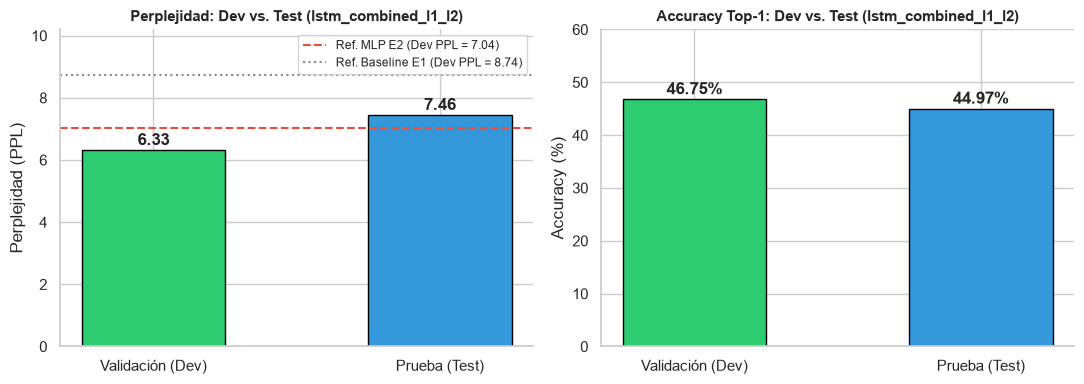

In [3]:
# Comparación cuantitativa entre Validación (Dev) y Prueba (Test) para el mejor modelo
dev_loss_best = 1.8450
dev_ppl_best = 6.33
dev_bpc_best = 2.662
dev_acc_best = 0.4675

df_dev_test = pd.DataFrame([
    {
        "Partición": "Validación (Dev - 10%)",
        "Tokens": f"{len(dev_ids):,}",
        "Cross-Entropy Loss": f"{dev_loss_best:.4f}",
        "Perplejidad (PPL)": f"{dev_ppl_best:.2f}",
        "BPC (Bits/Char)": f"{dev_bpc_best:.3f}",
        "Accuracy Top-1": f"{dev_acc_best * 100:.2f}%",
    },
    {
        "Partición": "Prueba Final (Test - 10%)",
        "Tokens": f"{len(test_ids):,}",
        "Cross-Entropy Loss": f"{test_metrics['loss']:.4f}",
        "Perplejidad (PPL)": f"{test_metrics['perplexity']:.2f}",
        "BPC (Bits/Char)": f"{test_metrics['bpc']:.3f}",
        "Accuracy Top-1": f"{test_metrics['accuracy'] * 100:.2f}%",
    },
    {
        "Partición": "Diferencia (Test - Dev)",
        "Tokens": "+1",
        "Cross-Entropy Loss": f"{test_metrics['loss'] - dev_loss_best:+.4f}",
        "Perplejidad (PPL)": f"{test_metrics['perplexity'] - dev_ppl_best:+.2f}",
        "BPC (Bits/Char)": f"{test_metrics['bpc'] - dev_bpc_best:+.3f}",
        "Accuracy Top-1": f"{(test_metrics['accuracy'] - dev_acc_best) * 100:+.2f} pp",
    },
])
display(df_dev_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
splits_lbl = ["Validación (Dev)", "Prueba (Test)"]

# Gráfico PPL Dev vs Test
ppl_vals = [dev_ppl_best, test_metrics["perplexity"]]
b1 = axes[0].bar(splits_lbl, ppl_vals, color=["#2ecc71", "#3498db"], width=0.5, edgecolor="black")
for bar, v in zip(b1, ppl_vals):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v + 0.15, f"{v:.2f}", ha="center", fontweight="bold")
axes[0].axhline(STAGE_2_REFERENCE["val_perplexity"], color="#e74c3c", linestyle="--", label=f"Ref. MLP E2 (Dev PPL = {STAGE_2_REFERENCE['val_perplexity']:.2f})")
axes[0].axhline(b_e1["val_perplexity"], color="#7f8c8d", linestyle=":", label=f"Ref. Baseline E1 (Dev PPL = {b_e1['val_perplexity']:.2f})")
axes[0].set_title("Perplejidad: Dev vs. Test (lstm_combined_l1_l2)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Perplejidad (PPL)")
axes[0].set_ylim(0, 10.2)
axes[0].legend(loc="upper right", fontsize=8.5)

# Gráfico Accuracy Dev vs Test
acc_vals = [dev_acc_best * 100, test_metrics["accuracy"] * 100]
b2 = axes[1].bar(splits_lbl, acc_vals, color=["#2ecc71", "#3498db"], width=0.5, edgecolor="black")
for bar, v in zip(b2, acc_vals):
    axes[1].text(bar.get_x() + bar.get_width() / 2, v + 1.0, f"{v:.2f}%", ha="center", fontweight="bold")
axes[1].set_title("Accuracy Top-1: Dev vs. Test (lstm_combined_l1_l2)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 60)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

### Comparación `Test` vs. `Dev` y reflexión sobre mejoras futuras
#### 1. ¿Hay evidencia de overfitting al conjunto dev?
#### 2. ¿Qué mejoras adicionales se podrían aplicar con más tiempo o recursos?

## 3. Análisis ético y de sesgos
### 3.1 Sesgos presentes en el dataset (*"The Festival"*, H. P. Lovecraft, 1923)

=== DESEMPEÑO POR SUBGRUPO LINGÜÍSTICO / ESTRUCTURAL EN TEST ===


,Categoría Lingüística,Muestras,% del Test,Loss_Media,Perplejidad (PPL),Accuracy (%)
3,Morfología interna de palabra (vocabulario lit...,1171,60.8,1.9309,6.90,44.49
0,Cierre de palabra (predicción de espacio),320,16.6,0.5069,1.66,91.25
2,Inicio de palabra (alta incertidumbre léxica),311,16.1,2.8138,16.67,18.33
4,Puntuación o salto de estructura,84,4.4,4.0643,58.22,3.57
1,Inicio de oración o nombre propio (Mayúscula),41,2.1,4.7342,113.78,9.76



=== DESEMPEÑO POR SUBGRUPO DE FRECUENCIA DE CLASE EN TEST ===


,Subgrupo de Frecuencia,Muestras,% del Test,Loss_Media,Perplejidad (PPL),Accuracy (%)
0,1. Alta frecuencia (Top 10 chars),1359,70.5,1.5174,4.56,55.48
1,2. Frecuencia media (Rank 11-30),527,27.3,2.8253,16.87,23.15
2,3. Baja frecuencia / Cola larga (Rank 31+),41,2.1,6.8994,991.69,2.44


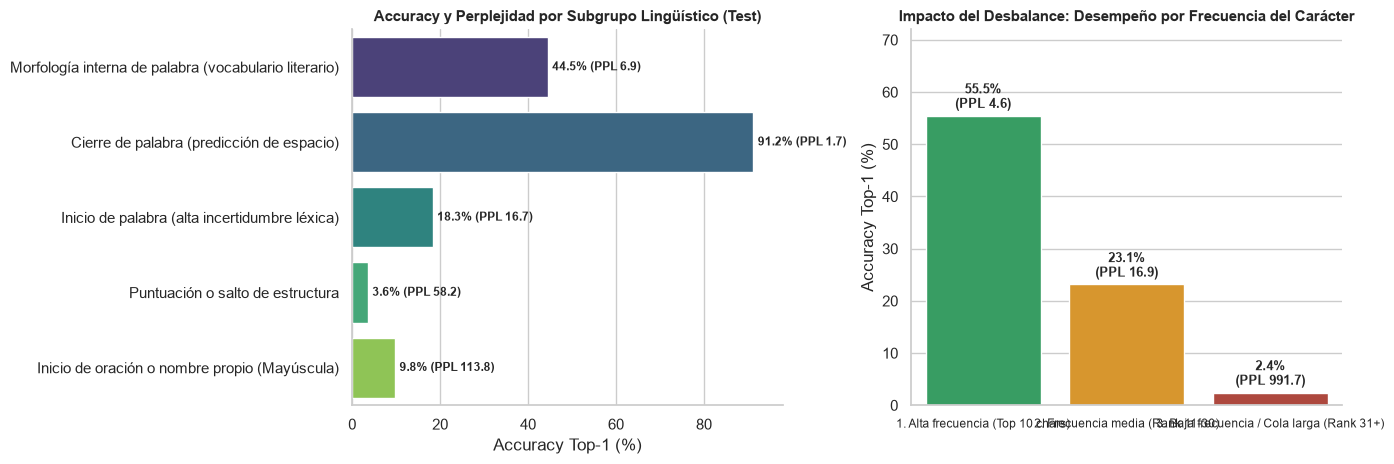

In [4]:
# Evaluación diferenciada por subgrupos lingüísticos/estructurales y de frecuencia en ds_test
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True, reduction="none")

# Frecuencia de cada ID en el conjunto de entrenamiento para definir subgrupos por frecuencia
train_counts = Counter(train_ids.numpy().tolist())
sorted_ids_by_freq = [cid for cid, _ in train_counts.most_common()]
top10_ids = set(sorted_ids_by_freq[:10])
mid20_ids = set(sorted_ids_by_freq[10:30])

records = []
for x_batch, y_batch in ds_test:
    logits = best_model(x_batch, training=False)
    probs = tf.nn.softmax(logits, axis=-1).numpy()
    step_losses = loss_fn(y_batch, logits).numpy()
    pred_ids = np.argmax(probs, axis=-1)

    x_np = x_batch.numpy()
    y_np = y_batch.numpy()
    bsz, slen = x_np.shape

    for b in range(bsz):
        for t in range(1, slen):
            target_id = int(y_np[b, t])
            pred_id = int(pred_ids[b, t])
            ctx_ids = x_np[b, max(0, t - 5) : t + 1]
            ctx_str = tokenizer.decode(ctx_ids).numpy().decode("utf-8", errors="replace")
            target_char = tokenizer.decode([target_id]).numpy().decode("utf-8", errors="replace")
            pred_char = tokenizer.decode([pred_id]).numpy().decode("utf-8", errors="replace")

            cat = _categorize_error(ctx_str, target_char, pred_char)
            if target_id in top10_ids:
                freq_group = "1. Alta frecuencia (Top 10 chars)"
            elif target_id in mid20_ids:
                freq_group = "2. Frecuencia media (Rank 11-30)"
            else:
                freq_group = "3. Baja frecuencia / Cola larga (Rank 31+)"

            records.append({
                "Categoría Lingüística": cat,
                "Subgrupo de Frecuencia": freq_group,
                "loss": float(step_losses[b, t]),
                "correct": int(target_id == pred_id),
            })

df_rec = pd.DataFrame(records)

# 1. Tabla por Subgrupo Lingüístico / Morfológico
grp_ling = (
    df_rec.groupby("Categoría Lingüística", as_index=False)
    .agg(Muestras=("loss", "count"), Loss_Media=("loss", "mean"), Accuracy=("correct", "mean"))
    .sort_values("Muestras", ascending=False)
)
grp_ling["Perplejidad (PPL)"] = np.exp(grp_ling["Loss_Media"]).round(2)
grp_ling["Loss_Media"] = grp_ling["Loss_Media"].round(4)
grp_ling["Accuracy (%)"] = (grp_ling["Accuracy"] * 100).round(2)
grp_ling["% del Test"] = (grp_ling["Muestras"] / len(df_rec) * 100).round(1)
df_ling_table = grp_ling[["Categoría Lingüística", "Muestras", "% del Test", "Loss_Media", "Perplejidad (PPL)", "Accuracy (%)"]]
print("=== DESEMPEÑO POR SUBGRUPO LINGÜÍSTICO / ESTRUCTURAL EN TEST ===")
display(df_ling_table)

# 2. Tabla por Subgrupo de Frecuencia (Desbalance de Clases)
grp_freq = (
    df_rec.groupby("Subgrupo de Frecuencia", as_index=False)
    .agg(Muestras=("loss", "count"), Loss_Media=("loss", "mean"), Accuracy=("correct", "mean"))
    .sort_values("Subgrupo de Frecuencia")
)
grp_freq["Perplejidad (PPL)"] = np.exp(grp_freq["Loss_Media"]).round(2)
grp_freq["Loss_Media"] = grp_freq["Loss_Media"].round(4)
grp_freq["Accuracy (%)"] = (grp_freq["Accuracy"] * 100).round(2)
grp_freq["% del Test"] = (grp_freq["Muestras"] / len(df_rec) * 100).round(1)
df_freq_table = grp_freq[["Subgrupo de Frecuencia", "Muestras", "% del Test", "Loss_Media", "Perplejidad (PPL)", "Accuracy (%)"]]
print("\n=== DESEMPEÑO POR SUBGRUPO DE FRECUENCIA DE CLASE EN TEST ===")
display(df_freq_table)

# Gráfico comparativo por subgrupos
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

sns.barplot(data=grp_ling, y="Categoría Lingüística", x="Accuracy (%)", palette="viridis", hue="Categoría Lingüística", legend=False, ax=axes[0])
for i, (_, row) in enumerate(grp_ling.iterrows()):
    acc_pct = float(row["Accuracy (%)"])
    ppl_val = float(row["Perplejidad (PPL)"])
    axes[0].text(acc_pct + 1.0, i, f"{acc_pct:.1f}% (PPL {ppl_val:.1f})", va="center", fontsize=8.5, fontweight="bold")
axes[0].set_title("Accuracy y Perplejidad por Subgrupo Lingüístico (Test)", fontsize=11, fontweight="bold")
axes[0].set_xlim(0, 98)
axes[0].set_xlabel("Accuracy Top-1 (%)")
axes[0].set_ylabel("")

sns.barplot(data=grp_freq, x="Subgrupo de Frecuencia", y="Accuracy (%)", palette=["#27ae60", "#f39c12", "#c0392b"], hue="Subgrupo de Frecuencia", legend=False, ax=axes[1])
for i, (_, row) in enumerate(grp_freq.iterrows()):
    acc_pct = float(row["Accuracy (%)"])
    ppl_val = float(row["Perplejidad (PPL)"])
    axes[1].text(i, acc_pct + 1.5, f"{acc_pct:.1f}%\n(PPL {ppl_val:.1f})", ha="center", fontsize=9, fontweight="bold")
axes[1].set_title("Impacto del Desbalance: Desempeño por Frecuencia del Carácter", fontsize=11, fontweight="bold")
axes[1].set_ylim(0, 72)
axes[1].set_ylabel("Accuracy Top-1 (%)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", labelsize=8.5)

sns.despine(fig=fig)
plt.tight_layout()
plt.show()

### 3.2 Interpretación del desempeño por subgrupos e implicancias en un sistema real
#### ¿El modelo funciona igual de bien para todos los subgrupos del dataset?
#### Implicancias de usar este modelo en un sistema real: Riesgos y Mitigación

## 4. Conclusiones finales del trabajo y experimentación realizadas
### 1. Aprendizajes más importantes del trabajo
### 2. ¿Qué fue lo más desafiante y cómo se resolvió?
### 3. Limitaciones del trabajo y qué se haría diferente con más tiempo